### Time-Since-Maintenance Linear Degradation Model
Three Critical Patterns were observed\
    - 24/03/2026: SE jumped to 128%.\
    - The baseline performance declines steadily at roughly 0.13% to 0.19% per day, dropping by about 1% every 7 to 8 days down to 83% on 15/11/2026.\
    - Brief drops to 0% or ~45% (such as 15/06/2026, 25/08/2026, and 05/10/2026) represent temporary shutdowns or partial-load days. \
    Immediately afterward,  the pump returns to its normal degradation line, so filtering out these temporary outages allows the model to predict true operating health

In [1]:
# Load and Clean the Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 1. Load the dataset
df = pd.read_csv('Pump_SE_CSV.csv')

# 2. Parse dates (dayfirst=True is required for DD/MM/YYYY format)
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# 3. Convert '85%' string to float 85.0
df['SE'] = df['System Effectiveness'].str.rstrip('%').astype(float)

# Sort chronologically and inspect
df = df.sort_values('Date').reset_index(drop=True)
df.head()

,Date,System Effectiveness,SE
0,2026-01-01,85%,85.0
1,2026-01-02,84%,84.0
2,2026-01-03,84%,84.0
3,2026-01-04,84%,84.0
4,2026-01-05,84%,84.0


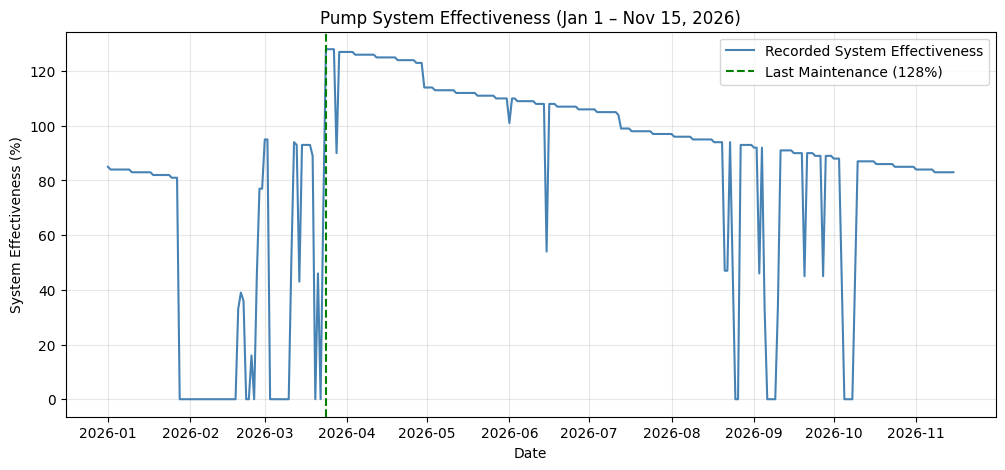

In [2]:
#Visualize the Historical Pattern. Plot the raw series to confirms where maintenance occurred and highlights the temporary downtime dips
plt.figure(figsize=(12, 5))
plt.plot(df['Date'], df['SE'], label='Recorded System Effectiveness', color='steelblue')
plt.axvline(pd.to_datetime('2026-03-24'), color='green', linestyle='--', label='Last Maintenance (128%)')
plt.title('Pump System Effectiveness (Jan 1 – Nov 15, 2026)')
plt.xlabel('Date')
plt.ylabel('System Effectiveness (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [3]:
# 1. Keep only data from the latest maintenance cycle (March 24, 2026 onward)
last_maintenance_date = pd.to_datetime('2026-03-24')
cycle_df = df[df['Date'] >= last_maintenance_date].copy()

# 2. Create a numerical feature: Days since last maintenance
cycle_df['Days_Since_Maintenance'] = (cycle_df['Date'] - last_maintenance_date).dt.days

# 3. Filter out temporary downtime/partial-load dips (< 80%)
train_df = cycle_df[cycle_df['SE'] >= 80].copy()

print(f"Training rows after filtering outages: {len(train_df)}")


Training rows after filtering outages: 216


(Note: If you specifically want to model the most recent regime from 13/07/2026 onward—where performance dropped from 99% to 83%—change last_maintenance_date in the filter to '2026-07-13', while still keeping Days_Since_Maintenance referenced to '2026-03-24'.)

In [4]:
#Train the Linear Degradation Model.Fit a simple linear regression model using Days_Since_Maintenance to predict SE
X_train = train_df[['Days_Since_Maintenance']]
y_train = train_df['SE']

model = LinearRegression()
model.fit(X_train, y_train)

daily_decay = model.coef_[0]
r2_score = model.score(X_train, y_train)

print(f"Estimated Daily Decay Rate: {daily_decay:.4f}% per day")
print(f"Model R² Score: {r2_score:.4f}")


Estimated Daily Decay Rate: -0.1907% per day
Model R² Score: 0.9296


In [5]:
# Generate 31 dates: Nov 16, 2026 + next 30 days (up to Dec 16, 2026)
future_dates = pd.date_range(start='2026-11-16', periods=31, freq='D')

future_df = pd.DataFrame({'Date': future_dates})
future_df['Days_Since_Maintenance'] = (future_df['Date'] - last_maintenance_date).dt.days

# Predict System Effectiveness
future_df['Predicted_SE (%)'] = model.predict(future_df[['Days_Since_Maintenance']]).round(2)

# Display the prediction for Nov 16 and the full 30-day forecast
print("Prediction for Nov 16, 2026:", future_df.iloc[0]['Predicted_SE (%)'], "%")
display(future_df[['Date', 'Predicted_SE (%)']])

# Optional: Save predictions to a new CSV file
future_df[['Date', 'Predicted_SE (%)']].to_csv('Pump_SE_30Day_Forecast.csv', index=False)


Prediction for Nov 16, 2026: 79.13 %


,Date,Predicted_SE (%)
0,2026-11-16,79.13
1,2026-11-17,78.94
2,2026-11-18,78.75
3,2026-11-19,78.56
4,2026-11-20,78.37
5,2026-11-21,78.18
6,2026-11-22,77.99
7,2026-11-23,77.80
8,2026-11-24,77.60
9,2026-11-25,77.41


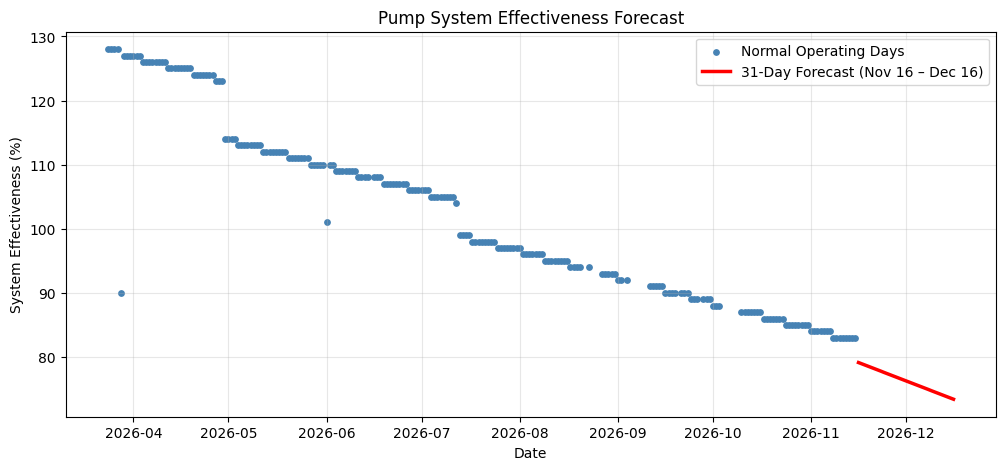

In [6]:
plt.figure(figsize=(12, 5))
plt.scatter(train_df['Date'], train_df['SE'], color='steelblue', s=15, label='Normal Operating Days')
plt.plot(future_df['Date'], future_df['Predicted_SE (%)'], color='red', linewidth=2.5, label='31-Day Forecast (Nov 16 – Dec 16)')
plt.title('Pump System Effectiveness Forecast')
plt.xlabel('Date')
plt.ylabel('System Effectiveness (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [7]:
# Would you like to include expected downtime probabilities (modeling those periodic 0% shutdown days)
# or adjust the notebook to automatically detect future maintenance spikes above 100%?

from sklearn.linear_model import LinearRegression

# Quick check of the steady decay rates from the dataset
# Notice:
# 24/03/2026: 128% -> 29/04/2026: 123% (5% drop over 36 days = -0.139%/day)
# 30/04/2026: 114% -> 12/07/2026: 104% (10% drop over 73 days = -0.137%/day)
# 13/07/2026: 99%  -> 15/11/2026: 83%  (16% drop over 125 days = -0.128%/day)
print("Decay rates:", round(-5/36, 4), round(-10/73, 4), round(-16/125, 4))
print("Nov 16 est from 83%:", round(83 - 0.13, 2))
print("Dec 16 est (31 days after Nov 15):", round(83 - 31 * 0.13, 2))


Decay rates: -0.1389 -0.137 -0.128
Nov 16 est from 83%: 82.87
Dec 16 est (31 days after Nov 15): 78.97
